# Laboratorio 11 · Guía 4 — Regresión Logística: de la Regresión a la Clasificación (Dirección y Régimen del Mercado)

**Curso:** Minería de Datos (DM + AIAP) · FISI · UNMSM · Semestre 2026-II · **Semana 12 del sílabo (Tema 12: Modelos de Regresión)**
**Docente:** Prof. Mg. Ing. Ernesto D. Cancho-Rodríguez, MBA (GWU)

**Fase CRISP-DM:** Modelado · Evaluación.

**Pregunta de negocio:** muchas decisiones de inversión son **binarias**: ¿comprar o no?, ¿cubrir el portafolio esta semana o no? La **regresión logística** toma la **combinación lineal** de las Guías 1 y 2 y la pasa por la **sigmoide** para obtener una **probabilidad**. Aquí se usa para dos preguntas: «¿**sube** SPY mañana?» (**Mundo 1**: ruido, la respuesta es que no se puede saber) y «¿la próxima semana será de **alta volatilidad**?» (**Mundo 3**: sí se puede). Esta guía es el **puente** hacia los **modelos de clasificación** del Tema 13.

**Estructura:** Parte I, la sigmoide, los **odds** y la **log-verosimilitud** · Parte II, **laboratorio de contraste sintético** (**Mundo 2**): umbral, curva ROC, calibración y regularización L1/L2 · Parte III, **dirección de SPY** (**Mundo 1**) · Parte IV, **régimen de volatilidad** (**Mundo 3**) con costos asimétricos.

> **Enfoque didáctico:** cada paso en su propia celda con sus `print`. Semilla `SEMILLA = 2026`. Precios hasta el 11-nov-2026. Las métricas de clasificación se presentan aquí de forma **introductoria**; el Tema 13 las profundiza.

# PARTE I — La Sigmoide, los Odds y la Verosimilitud

## 1. Librerías, Semilla y Datos

La **regresión logística** modela **P(y = 1 | x) = σ(z) = 1 / (1 + e^(−z))**, con **z = β₀ + β₁x₁ + … + βₚxₚ**. Equivalentemente, **ln[p / (1 − p)] = z**: el **logaritmo de los odds** (momios) es **lineal** en las variables. Cada **e^βⱼ** es una **razón de odds**: cuánto se multiplican los odds cuando xⱼ sube una unidad. Los coeficientes se estiman por **máxima verosimilitud**, minimizando la **pérdida logarítmica** (*log-loss*).

In [1]:
# Librerías del laboratorio
import warnings

warnings.filterwarnings("ignore")
import numpy as np  # cálculo numérico
import pandas as pd  # tablas
import matplotlib.pyplot as plt  # gráficos
import yfinance as yf  # precios de Yahoo Finance
import sklearn
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    log_loss,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss,
)
from sklearn.calibration import calibration_curve

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.dpi"] = 110
print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scikit-learn 1.3.1 | pandas 2.2.3


In [2]:
# Precios de cierre ajustado de 28 activos (Yahoo Finance). Plan B: CSV de respaldo del curso (carpeta D03)
TICKERS = [
    "SPY",
    "QQQ",
    "XLK",
    "XLF",
    "XLE",
    "XLV",
    "XLY",
    "XLP",
    "XLI",
    "XLU",
    "XLB",
    "XLRE",
    "XLC",
    "GLD",
    "TLT",
    "AAPL",
    "MSFT",
    "JPM",
    "XOM",
    "CAT",
    "KO",
    "PFE",
    "BVN",
    "FSM",
    "SCCO",
    "BHP",
    "B",
    "^VIX",
]
ARCH = "26.11.12.cierres_ajustados_28_activos_2010-01-04_2026-11-11.csv"
try:
    precios = yf.download(
        TICKERS, start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )["Close"].reindex(columns=TICKERS)
except Exception as e:
    precios = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if precios.empty or precios["SPY"].notna().sum() < 4000:
    precios = pd.read_csv(
        ARCH, index_col=0, parse_dates=True
    )  # súbalo a Colab si Yahoo no responde
    print("Se usó el CSV de respaldo:", ARCH)
precios.index = pd.to_datetime(precios.index)
print(
    "Dimensiones:",
    precios.shape,
    "| desde",
    precios.index.min().date(),
    "hasta",
    precios.index.max().date(),
)
print(
    "Días con precio de SPY:",
    int(precios["SPY"].notna().sum()),
    "| último cierre de SPY:",
    round(float(precios["SPY"].iloc[-1]), 2),
)

Dimensiones: (4243, 28) | desde 2010-01-04 hasta 2026-11-11
Días con precio de SPY: 4241 | último cierre de SPY: 759.81


In [3]:
# Precios OHLCV (apertura, máximo, mínimo, cierre, volumen) ajustados de SPY. Plan B: CSV de respaldo (D03)
ARCH_SPY = "26.11.12.SPY_OHLCV_ajustado_2010-01-04_2026-11-11.csv"
try:
    spy = yf.download(
        "SPY", start="2010-01-01", end="2026-11-12", auto_adjust=True, progress=False
    )
    spy.columns = [c[0] if isinstance(c, tuple) else c for c in spy.columns]
    spy = spy[["Open", "High", "Low", "Close", "Volume"]]
except Exception as e:
    spy = pd.DataFrame()
    print("Falló la descarga de Yahoo Finance:", e)
if spy.empty or len(spy) < 4000:
    spy = pd.read_csv(ARCH_SPY, index_col=0, parse_dates=True)
    print("Se usó el CSV de respaldo:", ARCH_SPY)
spy.index = pd.to_datetime(spy.index)
print(
    "SPY OHLCV:",
    spy.shape,
    "| desde",
    spy.index.min().date(),
    "hasta",
    spy.index.max().date(),
)
print(spy.tail(3).round(2))

SPY OHLCV: (4241, 5) | desde 2010-01-04 hasta 2026-11-11
              Open    High     Low   Close    Volume
Date                                                
2026-11-09  741.95  755.42  741.03  752.69  50281200
2026-11-10  747.94  752.14  744.86  749.92  40698600
2026-11-11  756.80  762.51  754.90  759.81  38854000


## 2. Por Qué No Basta una Recta: el Modelo Lineal de Probabilidad frente a la Sigmoide

> **Observación:** datos **sintéticos** de una sola variable, con **P(y = 1) = σ(−1 + 2x)** conocida, para ver la forma de la sigmoide.

Recta (modelo lineal de probabilidad): ŷ = 0.375 + 0.226·x  -> predicciones fuera de [0, 1]: 9.5% de los puntos
Logística: z = -0.796 + 1.517·x  (verdaderos: -1 y 2)
Razón de odds por unidad de x = e^β1 = 4.557: cada unidad de x multiplica los odds por 4.56


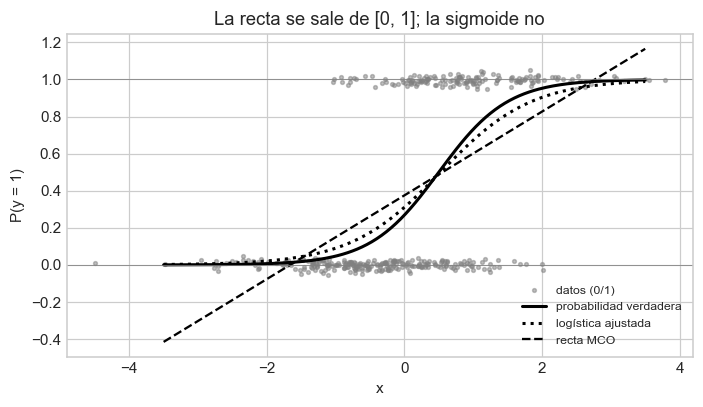

In [4]:
# Una variable: probabilidad verdadera sigmoide; comparación entre la recta (MCO sobre 0/1) y la logística
x1 = rng.normal(0, 1.2, 400)
p_verdadera = 1 / (1 + np.exp(-(-1 + 2 * x1)))
y1 = rng.binomial(1, p_verdadera)
recta = LinearRegression().fit(x1.reshape(-1, 1), y1)
logit = LogisticRegression(C=1e6).fit(
    x1.reshape(-1, 1), y1
)  # C enorme = sin regularización
print(
    f"Recta (modelo lineal de probabilidad): ŷ = {recta.intercept_:.3f} + "
    f"{recta.coef_[0]:.3f}·x  -> predicciones fuera de [0, 1]: "
    f"{np.mean((recta.predict(x1.reshape(-1, 1)) < 0) | (recta.predict(x1.reshape(-1, 1)) > 1)):.1%} "
    "de los puntos"
)
print(
    f"Logística: z = {logit.intercept_[0]:.3f} + {logit.coef_[0][0]:.3f}·x  "
    "(verdaderos: -1 y 2)"
)
print(
    f"Razón de odds por unidad de x = e^β1 = {np.exp(logit.coef_[0][0]):.3f}: cada "
    f"unidad de x multiplica los odds por {np.exp(logit.coef_[0][0]):.2f}"
)
xx = np.linspace(-3.5, 3.5, 200)
plt.figure(figsize=(6.5, 3.8))
plt.scatter(
    x1, y1 + rng.normal(0, 0.02, 400), s=6, color="gray", alpha=0.5, label="datos (0/1)"
)
plt.plot(
    xx,
    1 / (1 + np.exp(-(-1 + 2 * xx))),
    color="black",
    linewidth=2,
    label="probabilidad verdadera",
)
plt.plot(
    xx,
    logit.predict_proba(xx.reshape(-1, 1))[:, 1],
    color="black",
    linestyle=":",
    linewidth=2,
    label="logística ajustada",
)
plt.plot(
    xx,
    recta.predict(xx.reshape(-1, 1)),
    color="black",
    linestyle="--",
    label="recta MCO",
)
plt.axhline(0, color="gray", linewidth=0.5)
plt.axhline(1, color="gray", linewidth=0.5)
plt.xlabel("x")
plt.ylabel("P(y = 1)")
plt.legend(fontsize=8)
plt.title("La recta se sale de [0, 1]; la sigmoide no")
plt.tight_layout()
plt.show()

In [5]:
# La pérdida logarítmica (log-loss) a mano para tres predicciones
for p, y in [(0.9, 1), (0.9, 0), (0.5, 1)]:
    print(
        f"p = {p} | y = {y} | log-loss = -[y·ln p + (1-y)·ln(1-p)] = "
        f"{-(y * np.log(p) + (1 - y) * np.log(1 - p)):.4f}"
    )
print(
    "log-loss media del modelo logístico en sus datos = "
    f"{log_loss(y1, logit.predict_proba(x1.reshape(-1, 1))[:, 1]):.4f}"
)
print(
    f"log-loss de predecir siempre la proporción de unos ({y1.mean():.3f}) = "
    f"{log_loss(y1, np.full(len(y1), y1.mean())):.4f}"
)

p = 0.9 | y = 1 | log-loss = -[y·ln p + (1-y)·ln(1-p)] = 0.1054
p = 0.9 | y = 0 | log-loss = -[y·ln p + (1-y)·ln(1-p)] = 2.3026
p = 0.5 | y = 1 | log-loss = -[y·ln p + (1-y)·ln(1-p)] = 0.6931
log-loss media del modelo logístico en sus datos = 0.4592
log-loss de predecir siempre la proporción de unos (0.388) = 0.6676


**Interpretación de resultados:** la **recta** devuelve «probabilidades» **negativas o mayores que 1** para una parte de los puntos; la **sigmoide** queda siempre en (0, 1) y recupera los coeficientes verdaderos. La **log-loss** castiga con fuerza una predicción **confiada y equivocada** (p = 0,9 con y = 0 cuesta 2,30) y es la función que la regresión logística **minimiza**.

# PARTE II — Laboratorio de Contraste Sintético (Mundo 2)

> **Observación:** datos **sintéticos** (`make_classification`, semilla 2026) con **señal plantada** para ver umbral, ROC, calibración y regularización en un caso donde el modelo **funciona**.

## 3. Umbral, Matriz de Confusión y Curva ROC

In [6]:
# Datos sintéticos con señal: 2000 observaciones, 10 variables (4 informativas), 35 % de positivos
X_s, y_s = make_classification(
    n_samples=2000,
    n_features=10,
    n_informative=4,
    n_redundant=2,
    weights=[0.65, 0.35],
    class_sep=1.0,
    flip_y=0.05,
    random_state=SEMILLA,
)
Xs_ent, Xs_pru, ys_ent, ys_pru = train_test_split(
    X_s, y_s, test_size=0.3, stratify=y_s, random_state=SEMILLA
)
log_s = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(
    Xs_ent, ys_ent
)
prob_s = log_s.predict_proba(Xs_pru)[:, 1]
print("Proporción de positivos:", round(ys_pru.mean(), 3))
for umbral in [0.3, 0.5, 0.7]:
    pred = (prob_s >= umbral).astype(int)
    vn, fp, fn, vp = confusion_matrix(ys_pru, pred).ravel()
    print(
        f"umbral {umbral}: VP={vp:3d} FP={fp:3d} FN={fn:3d} VN={vn:3d} | "
        f"exactitud={accuracy_score(ys_pru, pred):.3f} "
        f"precisión={precision_score(ys_pru, pred):.3f} "
        f"exhaustividad={recall_score(ys_pru, pred):.3f} "
        f"F1={f1_score(ys_pru, pred):.3f}"
    )
print(
    f"AUC-ROC = {roc_auc_score(ys_pru, prob_s):.4f} | AUC-PR (precisión promedio) = "
    f"{average_precision_score(ys_pru, prob_s):.4f} | log-loss = "
    f"{log_loss(ys_pru, prob_s):.4f}"
)

Proporción de positivos: 0.363
umbral 0.3: VP=184 FP=126 FN= 34 VN=256 | exactitud=0.733 precisión=0.594 exhaustividad=0.844 F1=0.697
umbral 0.5: VP=150 FP= 69 FN= 68 VN=313 | exactitud=0.772 precisión=0.685 exhaustividad=0.688 F1=0.686
umbral 0.7: VP=104 FP= 32 FN=114 VN=350 | exactitud=0.757 precisión=0.765 exhaustividad=0.477 F1=0.588
AUC-ROC = 0.8434 | AUC-PR (precisión promedio) = 0.7392 | log-loss = 0.4807


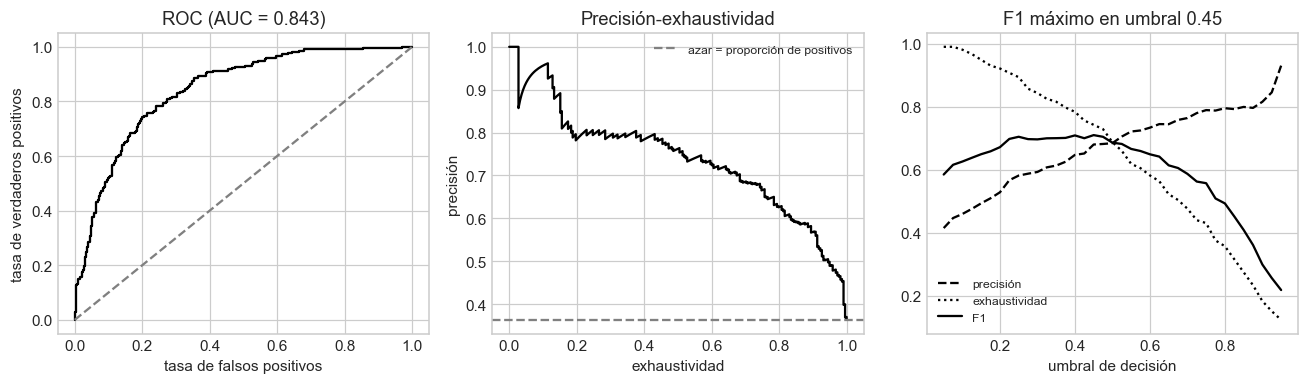

In [7]:
# Curva ROC, curva precisión-exhaustividad y métricas frente al umbral
fpr, tpr, _ = roc_curve(ys_pru, prob_s)
prec, rec, umb = precision_recall_curve(ys_pru, prob_s)
umbrales = np.linspace(0.05, 0.95, 37)
f1s = [f1_score(ys_pru, (prob_s >= u).astype(int)) for u in umbrales]
precs = [
    precision_score(ys_pru, (prob_s >= u).astype(int), zero_division=0)
    for u in umbrales
]
recs = [recall_score(ys_pru, (prob_s >= u).astype(int)) for u in umbrales]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
ax[0].plot(fpr, tpr, color="black")
ax[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
ax[0].set_xlabel("tasa de falsos positivos")
ax[0].set_ylabel("tasa de verdaderos positivos")
ax[0].set_title(f"ROC (AUC = {roc_auc_score(ys_pru, prob_s):.3f})")
ax[1].plot(rec, prec, color="black")
ax[1].axhline(
    ys_pru.mean(), color="gray", linestyle="--", label="azar = proporción de positivos"
)
ax[1].set_xlabel("exhaustividad")
ax[1].set_ylabel("precisión")
ax[1].set_title("Precisión-exhaustividad")
ax[1].legend(fontsize=8)
ax[2].plot(umbrales, precs, "--", color="black", label="precisión")
ax[2].plot(umbrales, recs, ":", color="black", label="exhaustividad")
ax[2].plot(umbrales, f1s, "-", color="black", label="F1")
ax[2].set_xlabel("umbral de decisión")
ax[2].set_title(f"F1 máximo en umbral {umbrales[int(np.argmax(f1s))]:.2f}")
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Interpretación de resultados:** la **probabilidad** es la salida del modelo; el **umbral** es una **decisión de negocio**. Bajar el umbral aumenta la **exhaustividad** (se detectan más positivos) y reduce la **precisión** (más falsas alarmas); el **AUC-ROC** resume la capacidad de **ordenar** positivos antes que negativos **sin fijar** umbral. Con **35 %** de positivos, la **exactitud** es una métrica razonable; con 2 % no lo sería (Tema 13).

## 4. Calibración y Regularización L1/L2 (el Puente con Ridge y Lasso)

 prob_media_predicha  fraccion_real_positivos
               0.019                    0.033
               0.056                    0.000
               0.115                    0.150
               0.185                    0.133
               0.259                    0.300
               0.388                    0.317
               0.513                    0.517
               0.662                    0.617
               0.815                    0.767
               0.944                    0.800
Puntaje de Brier = 0.1560 (0 = perfecto; 0.2313 = predecir siempre la base)


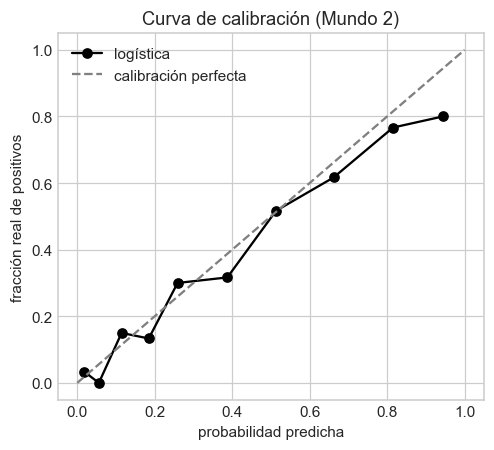

In [8]:
# Curva de calibración: ¿cuando el modelo dice 70 % ocurre el 70 % de las veces?
frac_pos, prob_media = calibration_curve(ys_pru, prob_s, n_bins=10, strategy="quantile")
print(
    pd.DataFrame(
        {"prob_media_predicha": prob_media, "fraccion_real_positivos": frac_pos}
    )
    .round(3)
    .to_string(index=False)
)
print(
    f"Puntaje de Brier = {brier_score_loss(ys_pru, prob_s):.4f} (0 = perfecto; "
    f"{brier_score_loss(ys_pru, np.full(len(ys_pru), ys_pru.mean())):.4f} = predecir "
    "siempre la base)"
)
plt.figure(figsize=(4.6, 4.2))
plt.plot(prob_media, frac_pos, "o-", color="black", label="logística")
plt.plot([0, 1], [0, 1], "--", color="gray", label="calibración perfecta")
plt.xlabel("probabilidad predicha")
plt.ylabel("fracción real de positivos")
plt.legend()
plt.title("Curva de calibración (Mundo 2)")
plt.tight_layout()
plt.show()

In [9]:
# Regularización: C = 1/alpha. L2 (como Ridge) encoge; L1 (como Lasso) anula coeficientes. 40 variables, 4 informativas
X_r, y_r = make_classification(
    n_samples=600,
    n_features=40,
    n_informative=4,
    n_redundant=0,
    class_sep=1.0,
    flip_y=0.05,
    random_state=SEMILLA,
)
Xr_ent, Xr_pru, yr_ent, yr_pru = train_test_split(
    X_r, y_r, test_size=0.3, stratify=y_r, random_state=SEMILLA
)
filas = []
for C_ in [0.01, 0.1, 1, 10, 1000]:
    l2 = make_pipeline(
        StandardScaler(), LogisticRegression(penalty="l2", C=C_, max_iter=2000)
    ).fit(Xr_ent, yr_ent)
    l1 = make_pipeline(
        StandardScaler(),
        LogisticRegression(penalty="l1", C=C_, solver="liblinear", max_iter=2000),
    ).fit(Xr_ent, yr_ent)
    filas.append(
        [
            C_,
            roc_auc_score(yr_pru, l2.predict_proba(Xr_pru)[:, 1]),
            int((np.abs(l2[-1].coef_) > 1e-6).sum()),
            roc_auc_score(yr_pru, l1.predict_proba(Xr_pru)[:, 1]),
            int((np.abs(l1[-1].coef_) > 1e-6).sum()),
        ]
    )
print(
    pd.DataFrame(
        filas, columns=["C", "AUC_L2", "coef_no_nulos_L2", "AUC_L1", "coef_no_nulos_L1"]
    )
    .round(4)
    .to_string(index=False)
)

      C  AUC_L2  coef_no_nulos_L2  AUC_L1  coef_no_nulos_L1
   0.01  0.7932                40  0.5000                 0
   0.10  0.7996                40  0.8381                14
   1.00  0.8073                40  0.8126                37
  10.00  0.8085                40  0.8086                39
1000.00  0.8082                40  0.8082                40


**Interpretación de resultados:** la logística está **bien calibrada** por construcción (minimiza la log-loss) y su **Brier** mejora claramente al de la base. En la regularización, **C pequeño** = penalización fuerte: **L2** mantiene las 40 variables encogidas (es **Ridge** para clasificación) y **L1** deja solo unas pocas (es **Lasso**), con un **AUC** similar; con 40 variables y 4 útiles, **L1** entrega el modelo **más interpretable**.

# PARTE III — ¿Sube SPY Mañana? (Mundo 1: ruido financiero)

**Conjunto de datos:** SPY (OHLCV) y VIX de **Yahoo Finance** 2012–2026; las 10 variables causales de las Guías 2 y 3. **Etiqueta:** 1 si el retorno de **mañana** es positivo. División **cronológica** 70/30.

## 5. Una Clasificación Honesta del Signo del Retorno

In [10]:
# Variables causales (solo pasado) y dos etiquetas futuras: dirección de mañana y régimen de volatilidad de la semana
r = (np.log(spy["Close"]).diff() * 100).loc["2012-01-01":]
vix = precios["^VIX"].reindex(r.index).ffill()
base = pd.DataFrame(
    {
        "ret_t": r,
        "ret_t1": r.shift(1),
        "abs_ret": r.abs(),
        "vol_5": r.rolling(5).std(),
        "vol_22": r.rolling(22).std(),
        "vol_66": r.rolling(66).std(),
        "vix": vix,
        "d_vix": vix.diff(),
        "parkinson": (
            np.log(spy["High"] / spy["Low"]).loc[r.index] / np.sqrt(4 * np.log(2)) * 100
        ),
    }
)
base["d_volumen"] = np.log(spy["Volume"]).diff().loc[r.index]
base["sube_manana"] = (r.shift(-1) > 0).astype(float)
base["vol_futura_5"] = r.shift(-5).rolling(5).std()
base = base.replace([np.inf, -np.inf], np.nan).dropna()
VARS = [
    "ret_t",
    "ret_t1",
    "abs_ret",
    "vol_5",
    "vol_22",
    "vol_66",
    "vix",
    "d_vix",
    "parkinson",
    "d_volumen",
]
corte = int(len(base) * 0.7)
ent, pru = base.iloc[:corte], base.iloc[corte:]
print(
    "Entrenamiento:",
    len(ent),
    "días hasta",
    ent.index.max().date(),
    "| Prueba:",
    len(pru),
    "días desde",
    pru.index.min().date(),
)
print(
    f"Proporción de días que SUBEN: entrenamiento = {ent['sube_manana'].mean():.3f} | "
    f"prueba = {pru['sube_manana'].mean():.3f}"
)

Entrenamiento: 2566 días hasta 2022-06-15 | Prueba: 1101 días desde 2022-06-16
Proporción de días que SUBEN: entrenamiento = 0.553 | prueba = 0.543


In [11]:
# Regresión logística para la dirección de mañana (C elegido con TimeSeriesSplit) frente a «siempre sube»
tscv = TimeSeriesSplit(n_splits=5, gap=1)
bus_dir = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    cv=tscv,
    scoring="roc_auc",
).fit(ent[VARS], ent["sube_manana"])
prob_dir = bus_dir.predict_proba(pru[VARS])[:, 1]
pred_dir = (prob_dir >= 0.5).astype(int)
print(
    "C elegido:",
    bus_dir.best_params_,
    f"| AUC de validación = {bus_dir.best_score_:.4f}",
)
print(
    f"PRUEBA: exactitud = {accuracy_score(pru['sube_manana'], pred_dir):.4f} | "
    f"AUC-ROC = {roc_auc_score(pru['sube_manana'], prob_dir):.4f} | "
    f"log-loss = {log_loss(pru['sube_manana'], prob_dir):.4f}"
)
print(
    f"Referencia «siempre sube»: exactitud = {pru['sube_manana'].mean():.4f} | "
    "log-loss = "
    f"{log_loss(pru['sube_manana'], np.full(len(pru), ent['sube_manana'].mean())):.4f}"
)
print(
    f"Probabilidades predichas: mínima = {prob_dir.min():.3f} | mediana = "
    f"{np.median(prob_dir):.3f} | máxima = {prob_dir.max():.3f}  (casi todas cerca de "
    "la base)"
)
vn, fp, fn, vp = confusion_matrix(pru["sube_manana"], pred_dir).ravel()
print(
    f"Matriz de confusión (umbral 0,5): VP={vp} FP={fp} FN={fn} VN={vn}  -> el modelo "
    "casi siempre predice «sube»"
)

C elegido: {'logisticregression__C': 10} | AUC de validación = 0.5228
PRUEBA: exactitud = 0.5295 | AUC-ROC = 0.4886 | log-loss = 0.6944
Referencia «siempre sube»: exactitud = 0.5431 | log-loss = 0.6896
Probabilidades predichas: mínima = 0.324 | mediana = 0.557 | máxima = 0.700  (casi todas cerca de la base)
Matriz de confusión (umbral 0,5): VP=558 FP=478 FN=40 VN=25  -> el modelo casi siempre predice «sube»


AUC real = 0.4886 | AUC con etiquetas barajadas: media = 0.5003, percentil 95 = 0.5222
Fracción de barajados con AUC >= real (valor p) = 0.785


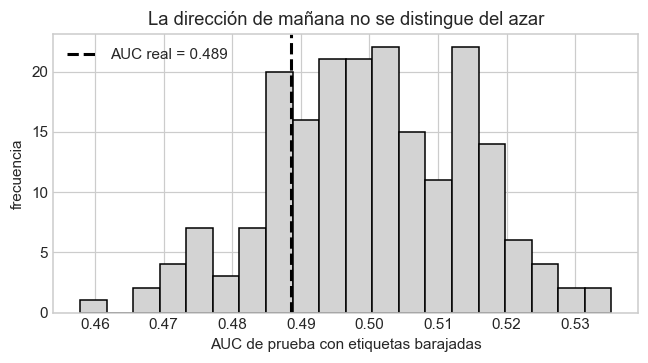

In [12]:
# Prueba de permutación: ¿el AUC de 0,5x es distinguible del azar? Se barajan las etiquetas 200 veces
aucs_nulos = []
for _ in range(200):
    y_bar = rng.permutation(ent["sube_manana"].values)
    m = make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=bus_dir.best_params_["logisticregression__C"], max_iter=2000
        ),
    ).fit(ent[VARS], y_bar)
    aucs_nulos.append(
        roc_auc_score(pru["sube_manana"], m.predict_proba(pru[VARS])[:, 1])
    )
auc_real = roc_auc_score(pru["sube_manana"], prob_dir)
print(
    f"AUC real = {auc_real:.4f} | AUC con etiquetas barajadas: media = "
    f"{np.mean(aucs_nulos):.4f}, percentil 95 = {np.percentile(aucs_nulos, 95):.4f}"
)
print(
    "Fracción de barajados con AUC >= real (valor p) = "
    f"{np.mean(np.array(aucs_nulos) >= auc_real):.3f}"
)
plt.figure(figsize=(6, 3.4))
plt.hist(aucs_nulos, bins=20, color="lightgray", edgecolor="black")
plt.axvline(
    auc_real,
    color="black",
    linestyle="--",
    linewidth=2,
    label=f"AUC real = {auc_real:.3f}",
)
plt.xlabel("AUC de prueba con etiquetas barajadas")
plt.ylabel("frecuencia")
plt.legend()
plt.title("La dirección de mañana no se distingue del azar")
plt.tight_layout()
plt.show()

**Interpretación de resultados:** la **exactitud** del modelo coincide con la de decir **«siempre sube»** (≈ 54 %, la **tasa base**), el **AUC** queda cerca de **0,5** y las probabilidades predichas se amontonan alrededor de la base: el modelo **no sabe nada** que no sepa la frecuencia histórica. La **prueba de permutación** confirma que ese AUC es **indistinguible** del que se obtiene con etiquetas **barajadas**. **Advertencia:** una exactitud de 54 % puede parecer «mejor que una moneda», pero la moneda correcta aquí es la **tasa base**, no 50 %.

# PARTE IV — ¿Será una Semana de Alta Volatilidad? (Mundo 3: señal real)

**Etiqueta:** 1 si la **volatilidad realizada de los próximos 5 días** supera el **percentil 75** del entrenamiento («semana agitada»). Un gestor que la anticipa puede **reducir exposición** o **comprar cobertura**.

## 6. Regresión Logística del Régimen de Volatilidad

In [13]:
# Etiqueta de régimen con umbral fijado SOLO con el entrenamiento (sin fuga)
p75 = ent["vol_futura_5"].quantile(0.75)
ent = ent.assign(agitada=(ent["vol_futura_5"] > p75).astype(int))
pru = pru.assign(agitada=(pru["vol_futura_5"] > p75).astype(int))
print(f"Percentil 75 de la volatilidad futura (entrenamiento) = {p75:.3f} % diario")
print(
    f"Proporción de semanas agitadas: entrenamiento = {ent['agitada'].mean():.3f} | "
    f"prueba = {pru['agitada'].mean():.3f}"
)
tscv5 = TimeSeriesSplit(n_splits=5, gap=5)
bus_reg = GridSearchCV(
    make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    {"logisticregression__C": [0.001, 0.01, 0.1, 1, 10]},
    cv=tscv5,
    scoring="roc_auc",
).fit(ent[VARS], ent["agitada"])
prob_reg = bus_reg.predict_proba(pru[VARS])[:, 1]
pred_reg = (prob_reg >= 0.5).astype(int)
print(
    "C elegido:",
    bus_reg.best_params_,
    f"| AUC de validación = {bus_reg.best_score_:.4f}",
)
print(
    f"PRUEBA: exactitud = {accuracy_score(pru['agitada'], pred_reg):.4f} | AUC-ROC = "
    f"{roc_auc_score(pru['agitada'], prob_reg):.4f} | "
    f"AUC-PR = {average_precision_score(pru['agitada'], prob_reg):.4f} | log-loss = "
    f"{log_loss(pru['agitada'], prob_reg):.4f}"
)
print(
    f"Referencia «nunca agitada»: exactitud = {1 - pru['agitada'].mean():.4f} | "
    f"AUC-PR del azar = {pru['agitada'].mean():.4f}"
)
vn, fp, fn, vp = confusion_matrix(pru["agitada"], pred_reg).ravel()
print(
    f"Matriz de confusión (umbral 0,5): VP={vp} FP={fp} FN={fn} VN={vn} | "
    f"precisión={precision_score(pru['agitada'], pred_reg):.3f} "
    f"exhaustividad={recall_score(pru['agitada'], pred_reg):.3f} "
    f"F1={f1_score(pru['agitada'], pred_reg):.3f}"
)

Percentil 75 de la volatilidad futura (entrenamiento) = 1.003 % diario
Proporción de semanas agitadas: entrenamiento = 0.250 | prueba = 0.282


C elegido: {'logisticregression__C': 0.1} | AUC de validación = 0.8434
PRUEBA: exactitud = 0.7784 | AUC-ROC = 0.8068 | AUC-PR = 0.6453 | log-loss = 0.4689
Referencia «nunca agitada»: exactitud = 0.7175 | AUC-PR del azar = 0.2825
Matriz de confusión (umbral 0,5): VP=119 FP=52 FN=192 VN=738 | precisión=0.696 exhaustividad=0.383 F1=0.494


In [14]:
# Coeficientes como razones de odds (variables estandarizadas: efecto de +1 desviación estándar)
coef = pd.Series(bus_reg.best_estimator_[-1].coef_[0], index=VARS)
tabla_or = pd.DataFrame(
    {"coeficiente": coef, "razon_de_odds": np.exp(coef)}
).sort_values("coeficiente", ascending=False)
print(tabla_or.round(3))

           coeficiente  razon_de_odds
vix              1.159          3.188
parkinson        0.395          1.484
vol_5            0.295          1.343
vol_22           0.162          1.175
d_vix           -0.021          0.979
abs_ret         -0.066          0.936
d_volumen       -0.069          0.934
ret_t1          -0.135          0.874
vol_66          -0.138          0.871
ret_t           -0.193          0.824


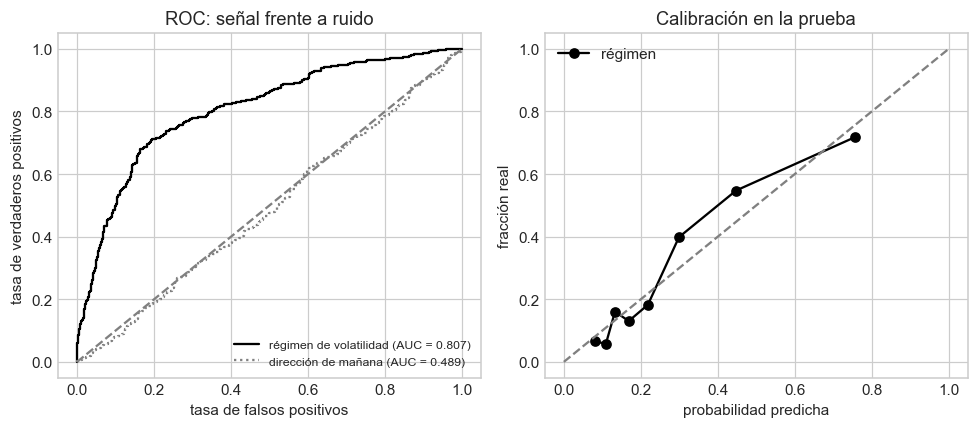

In [15]:
# Curva ROC del régimen frente a la dirección, y calibración del modelo de régimen
fpr_r, tpr_r, _ = roc_curve(pru["agitada"], prob_reg)
fpr_d, tpr_d, _ = roc_curve(pru["sube_manana"], prob_dir)
frac_pos, prob_media = calibration_curve(
    pru["agitada"], prob_reg, n_bins=8, strategy="quantile"
)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].plot(
    fpr_r,
    tpr_r,
    color="black",
    label=f"régimen de volatilidad (AUC = {roc_auc_score(pru['agitada'], prob_reg):.3f})",
)
ax[0].plot(
    fpr_d,
    tpr_d,
    color="gray",
    linestyle=":",
    label=f"dirección de mañana (AUC = {roc_auc_score(pru['sube_manana'], prob_dir):.3f})",
)
ax[0].plot([0, 1], [0, 1], "--", color="gray")
ax[0].set_xlabel("tasa de falsos positivos")
ax[0].set_ylabel("tasa de verdaderos positivos")
ax[0].legend(fontsize=8)
ax[0].set_title("ROC: señal frente a ruido")
ax[1].plot(prob_media, frac_pos, "o-", color="black", label="régimen")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_xlabel("probabilidad predicha")
ax[1].set_ylabel("fracción real")
ax[1].legend()
ax[1].set_title("Calibración en la prueba")
plt.tight_layout()
plt.show()

## 7. El Umbral como Decisión de Negocio: Costos Asimétricos

Suponga que **no cubrir** una semana agitada (falso negativo) cuesta **3 veces** más que **cubrir** una semana tranquila (falso positivo, se paga la prima de la cobertura). El umbral óptimo ya no es 0,5.

Umbral 0,50: costo = 628 (FP = 52, FN = 192, exhaustividad = 0.383)
Umbral óptimo = 0.27: costo = 432 (FP = 165, FN = 89, exhaustividad = 0.714)
Regla teórica: umbral = costo_FP / (costo_FP + costo_FN) = 1 / (1 + 3) = 0.25


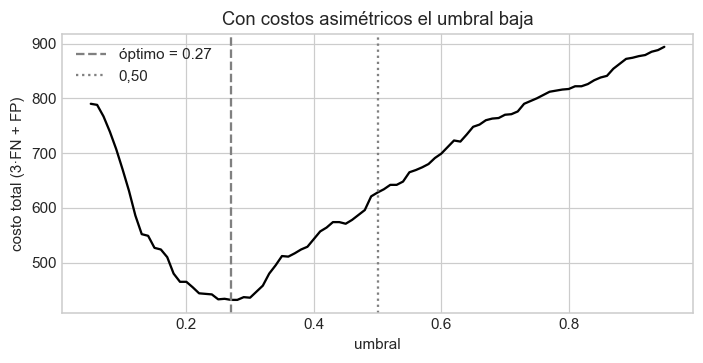

In [16]:
# Costo esperado por umbral con costo FN = 3 y costo FP = 1
costos = []
for u in np.linspace(0.05, 0.95, 91):
    pred = (prob_reg >= u).astype(int)
    vn, fp, fn, vp = confusion_matrix(pru["agitada"], pred).ravel()
    costos.append([u, 3 * fn + 1 * fp, fp, fn, recall_score(pru["agitada"], pred)])
costos = pd.DataFrame(
    costos, columns=["umbral", "costo_total", "FP", "FN", "exhaustividad"]
)
mejor = costos.loc[costos["costo_total"].idxmin()]
fila_05 = costos.iloc[(costos["umbral"] - 0.5).abs().idxmin()]
print(
    f"Umbral 0,50: costo = {fila_05['costo_total']:.0f} (FP = {fila_05['FP']:.0f}, FN "
    f"= {fila_05['FN']:.0f}, exhaustividad = {fila_05['exhaustividad']:.3f})"
)
print(
    f"Umbral óptimo = {mejor['umbral']:.2f}: costo = {mejor['costo_total']:.0f} (FP = "
    f"{mejor['FP']:.0f}, FN = {mejor['FN']:.0f}, exhaustividad = "
    f"{mejor['exhaustividad']:.3f})"
)
print(
    "Regla teórica: umbral = costo_FP / (costo_FP + costo_FN) = 1 / (1 + 3) = "
    f"{1 / 4:.2f}"
)
plt.figure(figsize=(6.5, 3.4))
plt.plot(costos["umbral"], costos["costo_total"], color="black")
plt.axvline(
    mejor["umbral"],
    color="gray",
    linestyle="--",
    label=f"óptimo = {mejor['umbral']:.2f}",
)
plt.axvline(0.5, color="gray", linestyle=":", label="0,50")
plt.xlabel("umbral")
plt.ylabel("costo total (3·FN + FP)")
plt.legend()
plt.title("Con costos asimétricos el umbral baja")
plt.tight_layout()
plt.show()

In [17]:
# Adelanto del Tema 13: la misma tarea con un clasificador de bosque aleatorio
rf = RandomForestClassifier(
    n_estimators=400, max_depth=6, min_samples_leaf=20, random_state=SEMILLA, n_jobs=-1
).fit(ent[VARS], ent["agitada"])
prob_rf = rf.predict_proba(pru[VARS])[:, 1]
print(
    f"Logística:      AUC = {roc_auc_score(pru['agitada'], prob_reg):.4f} | AUC-PR = "
    f"{average_precision_score(pru['agitada'], prob_reg):.4f} | Brier = "
    f"{brier_score_loss(pru['agitada'], prob_reg):.4f}"
)
print(
    f"Random Forest:  AUC = {roc_auc_score(pru['agitada'], prob_rf):.4f} | AUC-PR = "
    f"{average_precision_score(pru['agitada'], prob_rf):.4f} | Brier = "
    f"{brier_score_loss(pru['agitada'], prob_rf):.4f}"
)

Logística:      AUC = 0.8068 | AUC-PR = 0.6453 | Brier = 0.1518
Random Forest:  AUC = 0.8036 | AUC-PR = 0.6317 | Brier = 0.1517


**Interpretación de resultados:** el **régimen de volatilidad** sí se anticipa: el **AUC** es alto y la curva ROC se separa claramente de la de la **dirección**. Las **razones de odds** muestran que una desviación estándar más de **VIX** multiplica los odds de semana agitada varias veces. Con **costos asimétricos** (no cubrir cuesta 3×), el umbral óptimo cae hacia **0,25**, se **cubre más** y el costo total baja. El **bosque aleatorio** obtiene un AUC parecido: cuando la señal es **monótona**, la logística **basta** y además es **interpretable**. **Puente al Tema 13:** la próxima semana se comparan Random Forest, Gradient Boosting, XGBoost, SVM y Naive Bayes como clasificadores.

## 8. Actividad Autónoma

1. Cambie la etiqueta de régimen al **percentil 90** (semanas extremas, ~10 % de positivos). ¿Qué pasa con la **exactitud** de «nunca agitada», el **AUC-PR** y el umbral óptimo?
2. Repita la Parte III para **QQQ** y para **BVN**. ¿Alguna dirección se distingue del azar en la prueba de permutación?
3. Agregue la variable **ret_22** (retorno acumulado de 22 días) y compruebe con el AUC de validación si aporta algo al régimen.

**Entregable:** notebook ejecutado con la tabla de razones de odds del percentil 90 y un párrafo (≤ 150 palabras) que explique a un gestor la diferencia entre **predecir la dirección** y **predecir el riesgo**.